In [1]:
from ngsolve import *
import numpy as np
import ngsolve
from ngsolve.webgui import Draw
ngsglobals.msg_level = 1
import ipywidgets as widgets
import matplotlib.pyplot as plt

from domain import *
from implicit import implicit
from functions import *
#general parameters
sigma = 0 #switching parameter (0 e.g. if f is linear wrt q)
L = 1 #parameter if the functional in the u update is implemented as a simple multiplication

tstart = 0
tend = 100
tsteps = int(1e3)

t = Parameter(tstart) #time parameter that will be updated
dt = (tend-tstart)/tsteps

k = 3 # order of feses
maxh = 0.2 # mesh size for domain

In [2]:
# Choice of f
def f(q, u):
    gfg = GridFunction(Ufes)
    cfg = -u.Diff(x).Diff(x)-u.Diff(y).Diff(y) + q * u# + u**3 * norm(q)**(2/3) * q #example from paper, see remark 3.2
    gfg.Set(cfg)
    return gfg

class C:
    def __init__(self, q = 0, M = 1):
        if q:
            self.qn = norm(q)
        else:
            self.qn = 0
        self.M = M
        self.fes = Ufes

        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += self.M * Grad(self.fes.TrialFunction()) * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()

    def apply(self, f):
        return -self.M * (f.Diff(x).Diff(x) + f.Diff(y).Diff(y))
        #g = GridFunction(Ufes)
        #g.Set()
        #return g

    def solve(self, f): #Where is this used??? Maybe remove it.
        g = GridFunction(Ufes)
        g.vec.data = self.bilinearform.mat.Inverse(freedofs = Ufes.FreeDofs()) * LinearForm(f * self.fes.TestFunction() * dx).Assemble().vec
        return g

In [3]:
# Build domain
dom = domain(maxh = maxh, order = k)
mesh, Ufes, Qfes = dom.mesh, dom.Ufes, dom.Qfes

In [4]:
q_exact = sin(.5*x)*sin(.5*y) #exact q
q_norm = norm(q_exact,mesh)
Draw(q_exact,mesh)


WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

BaseWebGuiScene

In [5]:
# fabricated rhs

q_exact = sin(pi/3*x)*sin(pi/3*y) #exact q
q_norm = norm(q_exact,mesh)
Draw(q_exact,mesh)
qmin = -1
qmax = 1

u_exact_wot = sin(.5*x)*sin(.5*y) #exact u without time
u_exact = u_exact_wot*((t-tend)/(tend-tstart)) #exact u with time
u_exact_dt = u_exact.Diff(t)
"""
u_exact_wot = sin(.5*x)*sin(.5*y) #exact u without time
u_exact = [None for i in range (tsteps)]
#u_exact_dt = [None for i in range (tsteps)]
t.Set(0)
counter = 0
while counter<tsteps-dt:
    u_exact[counter] = GridFunction(Ufes) 
    u_exact[counter].Set(u_exact_wot*((t-tend)/(tend-tstart))) #exact u with time
    t.Set(t.Get()+dt)
    counter += 1
    #u_exact_dt = u_exact.Diff(t)  #still used???
t.Set(0)
"""
umin = -1
umax = 1

#Set up Gridfunctions, that will updated trough the time steps
gfu, gfq , z_old= GridFunction(Ufes), GridFunction(Qfes), GridFunction(Ufes)

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

In [6]:
# Implicit solvers
#ngsolve.SetHeapSize(10*1024*1024)  # 100 MB Heap
C0 = C()
implicit_u = implicit(bilinearform = C0.bilinearform, dt = dt) # If C were to depend on norm q, then this would need to be in the loop and updated each time - the implicit solver code isn't optimized for this yet!
implicit_q = implicit(bilinearform = None, fes = Qfes, dt = dt)             

99.8999999999986/100000

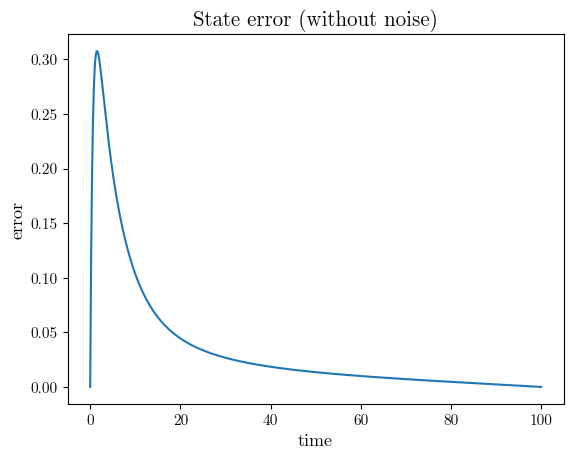

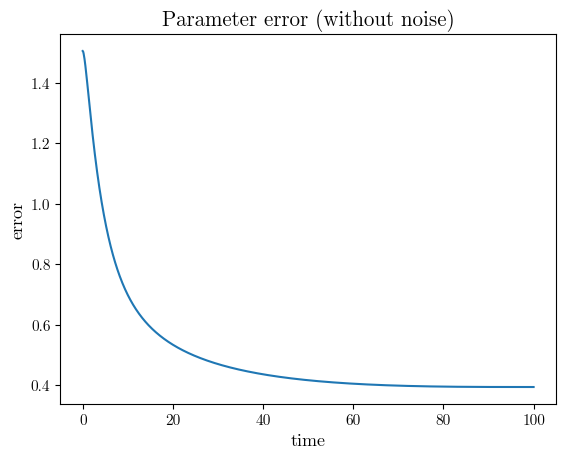

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

99.8999999999986/100000

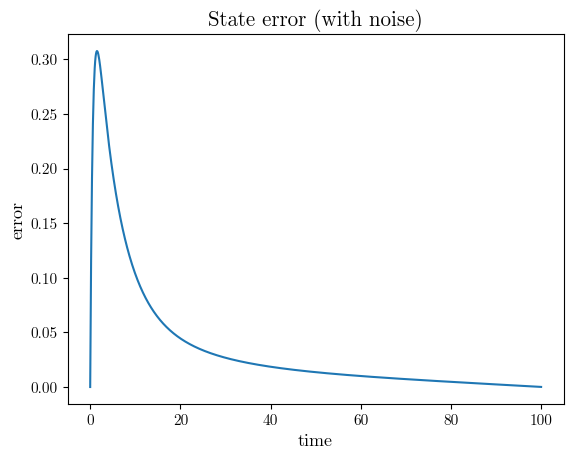

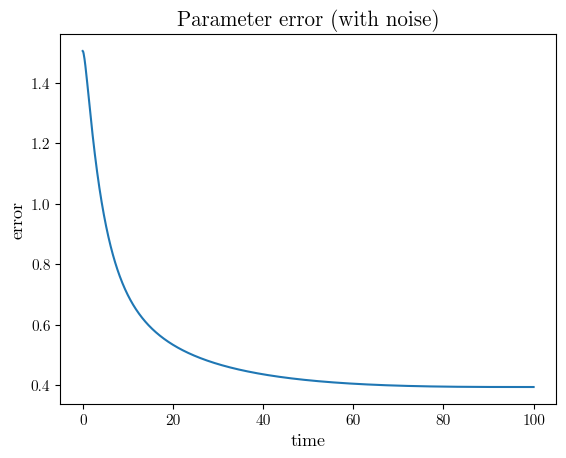

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

In [7]:
for noise_level in [0.0,0.03]:
    # Initial u and q
    t.Set(0)
    gfu.Set(u_exact)
    gfq.Set(q_exact*.5)
    #compute initial error
    error_u = [norm(gfu-u_exact, mesh)]
    error_q = [norm(gfq-q_exact, mesh)]
    saved_gfu = []
    saved_gfq = []
    while t < tend - dt:
        print("\r",t.Get(),"/",tend,sep="",end="")
        # Update time
        t += dt
        # Get updated data z and g
        #!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!1
        #!!!!!!!!!!!!need to add noise!!!!!!!!!!!!!!!!
        #!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!1
        auxil = GridFunction (Ufes)
        auxil.Set(u_exact)
        #z = add_noise(auxil,noise_level,Ufes,mesh)        
        z = u_exact
        #z =  add_noise(u_exact[int(t.Get()/dt)],noise_level,Ufes,mesh)
        #zt = GridFunction(Ufes)
        #zt.vec.data = z.vec.Copy()
        #dt.vec.data -= z_old.vec.Copy()#u_exact_dt[int(t.Get()/dt)]#
        #zt.vec.data /= dt
        #zt = u_exact_dt
        #z_old.vec.data = z.vec.Copy()

        g = u_exact_dt + f(q_exact,u_exact)
        
        # Implicit solve for u
        rhs_u = g - f(gfq,z) + C0.apply(z)
        implicit_u.solve_implicit(gfu, rhs_u) # Updates gfu behind the scenes
        error_u.append(norm(gfu-u_exact, mesh))
        saved_gfu.append(gfu.vec.FV().NumPy().copy())

        # Implicit solve for q
        f_deriv = u_exact * (gfu - u_exact) # + (z**3 * (3/2) * norm(q)**(-1/3) * q + z**3*norm(q)**(2/3))*(gfu-z) #add nonlinear part, check derivation
        rhs_q = f_deriv # -sigma*(zt-g) #nonlinear part, the sigma*f(q,z) part should remain implicit and still has to be coded
        implicit_q.solve_implicit(gfq, rhs_q) # Updates gfq behind the scenes
        error_q.append(norm(gfq-q_exact, mesh))
        saved_gfq.append(gfq.vec.FV().NumPy().copy())
    plot_error(tstart,tend,tsteps,noise_level,error_u,error_q)
    draw_gridfuncs (tsteps,u_exact,q_exact,gfu,gfq,mesh)
    save (mesh,noise_level,saved_gfu,saved_gfq)

In [8]:
Draw(gfu, min = umin, max = umax, settings={"Objects": {"Wireframe": False}}) #
Draw(gfq, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

BaseWebGuiScene

In [9]:
Draw(u_exact,mesh, min = umin, max = umax, settings={"Objects": {"Wireframe": False}})
Draw(q_exact,mesh, min = qmin, max = qmax, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

BaseWebGuiScene

In [10]:
Draw(gfu-u_exact,mesh, settings={"Objects": {"Wireframe": False}})
Draw(gfq-q_exact,mesh, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

BaseWebGuiScene